# Project 2 — Text-to-Image Generation
## Milestone 2: Integration & Training (Text-Conditional DDPM)

**IE 7615** — Project 2, Milestone 2

**David Fung**

This notebook integrates the CLIP text encoder (Milestone 1) with a from-scratch
denoising diffusion probabilistic model (DDPM) as the conditioning signal. We train a
text-conditional U-Net on the curated Flickr30k subset at 128x128 resolution so that
training fits within a modest compute budget. Classifier-free guidance (CFG) is enabled
by learning a null text token and dropping the caption embedding with a fixed probability
during training. This notebook builds directly on the dataset and CLIP pipeline from
Milestone 1 — it does not rebuild them.


In [11]:
import os
import time
import json
import math
import random
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from transformers import CLIPProcessor, CLIPModel

print(f"PyTorch:    {torch.__version__}")
print(f"CUDA:       {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU:        {torch.cuda.get_device_name(0)}")


PyTorch:    2.12.0+cu130
CUDA:       True
GPU:        NVIDIA GB10


In [42]:
# PROJECT CONSTANTS

GLOBAL_SEED = 42
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
torch.manual_seed(GLOBAL_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(GLOBAL_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# SMOKE_TEST True for a fast end-to-end sanity run (fewer epochs, smaller batch).
SMOKE_TEST = True

# Paths (relative to this notebook, Milestone_2/)
DATA_DIR      = "../data"
CURATED_DIR   = os.path.join(DATA_DIR, "curated")
MANIFEST_PATH = os.path.join(CURATED_DIR, "manifest.csv")
OUTPUT_DIR    = "outputs"
GALLERY_DIR   = "gallery"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(GALLERY_DIR, exist_ok=True)

# Models
#CLIP_MODEL_NAME = "openai/clip-vit-base-patch32"
#CLIP_TEXT_DIM   = 512 

CLIP_MODEL_NAME = "openai/clip-vit-large-patch14"
CLIP_TEXT_DIM   = 768

# DDPM configuration
IMG_SIZE       = 128  
IN_CHANNELS    = 3
BASE_CHANNELS  = 96                   # U-Net base width (64/128/256/512)
COND_DIM       = 256                  # conditioning vector dim (time + text)
N_TIMESTEPS    = 1000                 # diffusion length T
BETA_SCHEDULE  = "cosine"             # "linear" or "cosine"

# Training hyperparameters
BATCH_SIZE        = 32
EPOCHS            = 300 if not SMOKE_TEST else 65 # 50
LEARNING_RATE     = 1e-4
WEIGHT_DECAY      = 1e-2
TEXT_DROPOUT_PROB = 0.00 # 0.15             # CFG: replace caption embedding with null w.p. this
EMA_DECAY         = 0.999
GRAD_CLIP         = 1.0
VAL_FRACTION      = 0.10              # held-out validation fraction
SAMPLE_EVERY      = 1                 # generate a validation grid every N epochs

print(f"Device:             {DEVICE}")
print(f"Smoke test:         {SMOKE_TEST}")
print(f"Image size:         {IMG_SIZE}x{IMG_SIZE}")
print(f"Beta schedule:      {BETA_SCHEDULE}")
print(f"Batch size / Epochs:{BATCH_SIZE} / {EPOCHS}")
print(f"Text dropout (CFG): {TEXT_DROPOUT_PROB}")


Device:             cuda
Smoke test:         True
Image size:         128x128
Beta schedule:      cosine
Batch size / Epochs:32 / 50
Text dropout (CFG): 0.15


## Task 1 — Data Preparation & Text Embeddings

Read the image–caption manifest produced by Milestone 1, split it into train/val,
precompute and cache the frozen CLIP text embeddings once, and build a PyTorch dataset
that yields (32x32 image, 512-dim text embedding) pairs.


In [39]:
def clean_caption(text):
    """Light, whitespace-safe normalisation before CLIP encoding."""
    text = str(text).strip().lower()
    return ' '.join(text.split())          # collapses newlines / repeated spaces

def load_manifest(path):
    df = pd.read_csv(path)
    df = df.drop_duplicates(subset=['image_id']).reset_index(drop=True)
    return df

df_manifest = load_manifest(MANIFEST_PATH)
df_manifest['caption'] = df_manifest['caption'].apply(clean_caption)
print(f"Loaded {len(df_manifest)} curated pairs from {MANIFEST_PATH}")
print(f"Caption length (words): min={df_manifest['caption'].str.split().str.len().min()}, "
      f"max={df_manifest['caption'].str.split().str.len().max()}")
print(df_manifest.head())

# Deterministic train/val split (last VAL_FRACTION of rows -> val)
split    = int(round(len(df_manifest) * (1 - VAL_FRACTION)))
df_train = df_manifest.iloc[:split].reset_index(drop=True)
# Only for testing!
#df_train = df_val.iloc[:4].repeat(3750)   # 15,000 samples = 234 steps/epoch @ batch 64
df_val   = df_manifest.iloc[split:].reset_index(drop=True)
print(f"\nTrain: {len(df_train)}   Val: {len(df_val)}")


Loaded 5000 curated pairs from ../data/curated/manifest.csv
Caption length (words): min=8, max=78
   image_id                                            caption
0         0  two young guys with shaggy hair look at their ...
1         1  several men in hard hats are operating a giant...
2         2  a child in a pink dress is climbing up a set o...
3         3  someone in a blue shirt and hat is standing on...
4         4  two men, one in a gray shirt, one in a black s...

Train: 4500   Val: 500


In [40]:
import os, glob
for f in glob.glob(os.path.join(OUTPUT_DIR, "clip_text_embeddings_*.npy")):
    os.remove(f)
    print(f"Deleted {f}")

Deleted outputs/clip_text_embeddings_train.npy
Deleted outputs/clip_text_embeddings_val.npy


In [43]:
clip_model     = CLIPModel.from_pretrained(CLIP_MODEL_NAME).to(DEVICE)
clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_NAME)
clip_model.eval()
for p in clip_model.parameters():
    p.requires_grad_(False)

def encode_captions(texts, batch_size=64):
    embs = []
    for i in range(0, len(texts), batch_size):
        # ADD truncation=True and max_length=77 here
        inputs = clip_processor(
            text=texts[i:i+batch_size], 
            return_tensors="pt",
            padding=True, 
            truncation=True,      # <--- Fix 1: Enable truncation
            max_length=77         # <--- Fix 2: Match CLIP's limit
        ).to(DEVICE)
        
        with torch.no_grad():
            out = clip_model.get_text_features(**inputs)           
            if out.dim() == 3:          # (B, 77, 512) — full sequence
                out = out[:, 0, :]      # CLS token → (B, 512)
            out = torch.nn.functional.normalize(out, dim=-1)
        embs.append(out.cpu().numpy())
    return np.concatenate(embs, axis=0).astype(np.float32)

def encode_captions_tokens(texts, batch_size=64):
    embs = []
    for i in range(0, len(texts), batch_size):
        inputs = clip_processor(
            text=texts[i:i+batch_size],
            return_tensors="pt",
            padding="max_length",     # ← THE FIX: pad every seq to exactly 77
            truncation=True,
            max_length=77
        ).to(DEVICE)
        with torch.no_grad():
            out = clip_model.text_model(
                input_ids=inputs['input_ids'],
                attention_mask=inputs['attention_mask']
            ).last_hidden_state          # (B, 77, 768) — fixed length now
        embs.append(out.cpu().numpy())
    return np.concatenate(embs, axis=0).astype(np.float32)

emb_train_path = os.path.join(OUTPUT_DIR, "clip_text_embeddings_train.npy")
emb_val_path   = os.path.join(OUTPUT_DIR, "clip_text_embeddings_val.npy")

if os.path.exists(emb_train_path) and os.path.exists(emb_val_path):
    train_emb = np.load(emb_train_path)
    val_emb   = np.load(emb_val_path)
    print("Loaded cached CLIP text embeddings.")
else:
    print("Computing CLIP text embeddings...")
    train_emb = encode_captions(df_train['caption'].tolist())
    val_emb   = encode_captions(df_val['caption'].tolist())
    np.save(emb_train_path, train_emb)
    np.save(emb_val_path, val_emb)
    print(f"Saved {train_emb.shape[0]} train + {val_emb.shape[0]} val embeddings.")

print(f"Train embeddings: {train_emb.shape}, dtype={train_emb.dtype}, "
      f"norm={np.linalg.norm(train_emb, axis=1).mean():.3f}")
print(f"Val embeddings:   {val_emb.shape}, dtype={val_emb.dtype}, "
      f"norm={np.linalg.norm(val_emb, axis=1).mean():.3f}")

tok_train_path = os.path.join(OUTPUT_DIR, "clip_text_tokens_train.npy")
tok_val_path   = os.path.join(OUTPUT_DIR, "clip_text_tokens_val.npy")
if os.path.exists(tok_train_path) and os.path.exists(tok_val_path):
    train_tok = np.load(tok_train_path)
    val_tok   = np.load(tok_val_path)
    print("Loaded cached CLIP text tokens.")
else:
    print("Computing CLIP text tokens...")
    train_tok = encode_captions_tokens(df_train['caption'].tolist())
    val_tok   = encode_captions_tokens(df_val['caption'].tolist())
    np.save(tok_train_path, train_tok)
    np.save(tok_val_path, val_tok)
    print(f"Saved {train_tok.shape[0]} train + {val_tok.shape[0]} val token sequences.")
print(f"Train tokens: {train_tok.shape}, dtype={train_tok.dtype}")
print(f"Val tokens:   {val_tok.shape}, dtype={val_tok.dtype}")


del clip_model, clip_processor
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Computing CLIP text embeddings...
Saved 4500 train + 500 val embeddings.
Train embeddings: (4500, 768), dtype=float32, norm=1.000
Val embeddings:   (500, 768), dtype=float32, norm=1.000
Loaded cached CLIP text tokens.
Train tokens: (4500, 77, 768), dtype=float32
Val tokens:   (500, 77, 768), dtype=float32


In [44]:
class CuratedTextImageDataset(Dataset):
    """Yields (32x32 image in [-1,1], 512-dim CLIP text embedding)."""
    def __init__(self, image_ids, text_embeddings, text_token_embeddings, img_dir, img_size, augment=False):
        self.image_ids = image_ids
        self.text_embeddings = np.asarray(text_embeddings, dtype=np.float32)
        self.text_token_embeddings = np.asarray(text_token_embeddings, dtype=np.float32) # Added for cross attention
        self.img_dir = img_dir
        self.img_size = img_size
        self.augment = augment

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        img = Image.open(os.path.join(self.img_dir, str(self.image_ids[idx]))).convert("RGB")
        img = img.resize((self.img_size, self.img_size), Image.BILINEAR)
        if self.augment and random.random() > 0.5:
            img = img.transpose(Image.FLIP_LEFT_RIGHT)
        x = np.asarray(img, dtype=np.float32) / 255.0
        x = (x - 0.5) / 0.5                       # -> [-1, 1]
        x = torch.from_numpy(x).permute(2, 0, 1)
        t = torch.from_numpy(self.text_embeddings[idx])
        tok = torch.from_numpy(self.text_token_embeddings[idx]) # Added for cross attention
        return x, t, tok

def make_loader(df, embeddings, token_embeddings, augment):
    ds = CuratedTextImageDataset(df['image_id'].tolist(), embeddings, token_embeddings, CURATED_DIR, IMG_SIZE, augment)
    g = torch.Generator(); g.manual_seed(GLOBAL_SEED)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=augment, num_workers=0,
                      drop_last=augment, generator=g, pin_memory=torch.cuda.is_available())

train_loader = make_loader(df_train, train_emb, train_tok, augment=True)
val_loader   = make_loader(df_val,   val_emb, val_tok,  augment=False)

x0, t0, tok0 = next(iter(train_loader))
#print(f"Sample batch: image {tuple(x0.shape)}, text {tuple(t0.shape)}")
print(f"Sample batch: image {tuple(x0.shape)}, text {tuple(t0.shape)}, tokens {tuple(tok0.shape)}")
print(f"Image range:  [{x0.min():.3f}, {x0.max():.3f}]")
print(f"Text L2 norm: {t0.norm(dim=1).mean().item():.3f}")


Sample batch: image (32, 3, 128, 128), text (32, 768), tokens (32, 77, 768)
Image range:  [-1.000, 1.000]
Text L2 norm: 1.000


## Task 2 — Text-Conditional DDPM (architecture + diffusion process)

Build a U-Net noise-prediction network conditioned on the timestep and the CLIP text
embedding via adaptive group normalisation (AdaGN). We use a cosine noise schedule and
enable classifier-free guidance by learning a **null text token**: during training the
caption embedding is replaced by this token with probability `TEXT_DROPOUT_PROB`, so at
inference we can steer the denoising with `eps = eps_uncond + s * (eps_cond - eps_uncond)`.


In [45]:
def cosine_beta_schedule(T, s=0.008):
    steps = T + 1
    t = torch.linspace(0, 1, steps, dtype=torch.float64)
    alphas_cumprod = torch.cos((t + s) / (1 + s) * math.pi * 0.5) ** 2
    betas = 1 - (alphas_cumprod[1:] / alphas_cumprod[:-1])
    return torch.clip(betas, 0.0001, 0.9999).float()

def linear_beta_schedule(T):
    return torch.linspace(0.0001, 0.02, T).float()

class GaussianDiffusion:
    """Epsilon-prediction DDPM with cosine/linear beta schedules and DDIM sampling."""
    def __init__(self, T, schedule="cosine", device="cpu"):
        self.T = T
        self.device = device
        self.betas = (cosine_beta_schedule(T) if schedule == "cosine"
                      else linear_beta_schedule(T)).to(device)
        self.alphas = 1.0 - self.betas
        self.alphas_cumprod = torch.cumprod(self.alphas, dim=0)
        self.alphas_cumprod_prev = F.pad(self.alphas_cumprod[:-1], (1, 0))
        self.sqrt_alphas_cumprod = self.alphas_cumprod.sqrt()
        self.sqrt_one_minus_alphas_cumprod = (1.0 - self.alphas_cumprod).sqrt()
        self.sqrt_recip_alphas = self.alphas.reciprocal().sqrt()
        # Official DDPM posterior coefficients
        self.posterior_mean_coef1 = self.betas * (1.0 - self.alphas_cumprod_prev) / (1.0 - self.alphas_cumprod)
        self.posterior_mean_coef2 = self.alphas * (1.0 - self.alphas_cumprod_prev) / (1.0 - self.alphas_cumprod)
        self.posterior_var = self.betas * (1.0 - self.alphas_cumprod_prev) / (1.0 - self.alphas_cumprod)
    def q_sample(self, x0, t, noise):
        a = self.sqrt_alphas_cumprod[t][:, None, None, None]
        s = self.sqrt_one_minus_alphas_cumprod[t][:, None, None, None]
        return a * x0 + s * noise
    def loss(self, model, x0, text_emb, text_tokens, text_dropout_prob):
        """CFG-aware diffusion loss: drop the caption embedding for a random subset."""
        B = x0.shape[0]
        t = torch.randint(0, self.T, (B,), device=x0.device)
        noise = torch.randn_like(x0)
        xt = self.q_sample(x0, t, noise)
        use_null = (torch.rand(B, device=x0.device) < text_dropout_prob).float()
        cond_emb = text_emb * (1.0 - use_null[:, None]) + model.null_text * use_null[:, None]
        cond_tok = text_tokens * (1.0 - use_null[:, None, None])
        eps_pred = model(xt, t, cond_emb, cond_tok)
        return F.mse_loss(eps_pred, noise)
    def ddim_prev(self, xt, t, eps, a_prev, eta=0.0):
        """One DDIM reverse step (deterministic when eta=0)."""
        a_t = self.alphas_cumprod[t]
        x0_pred = (xt - self.sqrt_one_minus_alphas_cumprod[t] * eps) / self.sqrt_alphas_cumprod[t]
        x0_pred = torch.clamp(x0_pred, -1.0, 1.0)
        sigma = eta * ((1.0 - a_prev) / (1.0 - a_t)).sqrt() * (1.0 - a_t / a_prev).sqrt()
        dir_xt = (1.0 - a_prev - sigma ** 2).clamp(min=0.0).sqrt() * eps
        x_prev = a_prev.sqrt() * x0_pred + dir_xt
        if eta > 0:
            x_prev = x_prev + sigma * torch.randn_like(xt)
        return x_prev
    def sample(self, model, text_emb, text_tokens, null_emb, guidance_scale, n_steps, seed=42, eta=0.0,
               device="cpu", img_size=32, channels=3):
        """CFG + DDIM sampling of one image (batch=1)."""
        model.eval()
        if text_emb.dim() == 1:
            text_emb = text_emb.unsqueeze(0)
        if text_tokens.dim() == 2:
            text_tokens = text_tokens.unsqueeze(0)
        if null_emb.dim() == 1:
            null_emb = null_emb.unsqueeze(0)
        gen = torch.Generator().manual_seed(seed)
        step = max(1, self.T // n_steps)
        timesteps = list(range(self.T - step, -1, -step))
        x = torch.randn(1, channels, img_size, img_size, generator=gen).to(device)
        with torch.no_grad():
            for i, t in enumerate(timesteps):
                t_batch = torch.tensor([t], device=device)
                eps_cond   = model(x, t_batch, text_emb, text_tokens)
                eps_uncond = model(x, t_batch, null_emb, torch.zeros_like(text_tokens))
                eps = eps_uncond + guidance_scale * (eps_cond - eps_uncond)
                t_prev = timesteps[i + 1] if (i + 1) < len(timesteps) else 0
                a_prev = self.alphas_cumprod[t_prev]
                x = self.ddim_prev(x, t, eps, a_prev, eta)
        x = torch.clamp(x, -1.0, 1.0)
        return x

# Old
def cosine_beta_schedule(T, s=0.008):
    steps = T + 1
    t = torch.linspace(0, 1, steps, dtype=torch.float64)
    alphas_cumprod = torch.cos((t + s) / (1 + s) * math.pi * 0.5) ** 2
    betas = 1 - (alphas_cumprod[1:] / alphas_cumprod[:-1])
    return torch.clip(betas, 0.0001, 0.9999).float()

def linear_beta_schedule(T):
    return torch.linspace(0.0001, 0.02, T).float()

class GaussianDiffusion:
    """Epsilon-prediction DDPM with cosine/linear beta schedules and DDIM sampling."""
    def __init__(self, T, schedule="cosine", device="cpu"):
        self.T = T
        self.device = device
        self.betas = (cosine_beta_schedule(T) if schedule == "cosine"
                      else linear_beta_schedule(T)).to(device)
        self.alphas = 1.0 - self.betas
        self.alphas_cumprod = torch.cumprod(self.alphas, dim=0)
        self.alphas_cumprod_prev = F.pad(self.alphas_cumprod[:-1], (1, 0))
        self.sqrt_alphas_cumprod = self.alphas_cumprod.sqrt()
        self.sqrt_one_minus_alphas_cumprod = (1.0 - self.alphas_cumprod).sqrt()
        self.sqrt_recip_alphas = self.alphas.reciprocal().sqrt()
        # Official DDPM posterior coefficients
        self.posterior_mean_coef1 = self.betas * (1.0 - self.alphas_cumprod_prev) / (1.0 - self.alphas_cumprod)
        self.posterior_mean_coef2 = self.alphas * (1.0 - self.alphas_cumprod_prev) / (1.0 - self.alphas_cumprod)
        self.posterior_var = self.betas * (1.0 - self.alphas_cumprod_prev) / (1.0 - self.alphas_cumprod)

    def q_sample(self, x0, t, noise):
        a = self.sqrt_alphas_cumprod[t][:, None, None, None]
        s = self.sqrt_one_minus_alphas_cumprod[t][:, None, None, None]
        return a * x0 + s * noise

    def loss(self, model, x0, text_emb, text_tokens, text_dropout_prob):
        """CFG-aware diffusion loss: drop the caption embedding for a random subset."""
        B = x0.shape[0]
        t = torch.randint(0, self.T, (B,), device=x0.device)
        noise = torch.randn_like(x0)
        xt = self.q_sample(x0, t, noise)
        use_null = (torch.rand(B, device=x0.device) < text_dropout_prob).float()
        cond_emb = text_emb * (1.0 - use_null[:, None]) + model.null_text * use_null[:, None]
        cond_tok = text_tokens * (1.0 - use_null[:, None, None]) # Added for cross attention
        eps_pred = model(xt, t, cond_emb, cond_tok)
        #eps_pred = model(xt, t, cond_emb) removed for cross attention
        return F.mse_loss(eps_pred, noise)

    def ddim_prev(self, xt, t, eps, a_prev, eta=0.0):
        """One DDIM reverse step (deterministic when eta=0)."""
        a_t = self.alphas_cumprod[t]
        x0_pred = (xt - self.sqrt_one_minus_alphas_cumprod[t] * eps) / self.sqrt_alphas_cumprod[t]
        x0_pred = torch.clamp(x0_pred, -1.0, 1.0)
        sigma = eta * ((1.0 - a_prev) / (1.0 - a_t)).sqrt() * (1.0 - a_t / a_prev).sqrt()
        dir_xt = (1.0 - a_prev - sigma ** 2).clamp(min=0.0).sqrt() * eps
        x_prev = a_prev.sqrt() * x0_pred + dir_xt
        if eta > 0:
            x_prev = x_prev + sigma * torch.randn_like(xt)
        return x_prev

    def sample(self, model, text_emb, text_tokens, null_emb, guidance_scale, n_steps, seed=42, eta=0.0,
               device="cpu", img_size=32, channels=3):
        """CFG + DDIM sampling of one image (batch=1)."""
        model.eval()
        if text_emb.dim() == 1:
            text_emb = text_emb.unsqueeze(0)
        if text_tokens.dim() == 2: # Added for cross attention
            text_tokens = text_tokens.unsqueeze(0) # Added for cross attention
        if null_emb.dim() == 1:
            null_emb = null_emb.unsqueeze(0)
        gen = torch.Generator().manual_seed(seed)
        step = max(1, self.T // n_steps)
        timesteps = list(range(self.T - step, -1, -step))
        x = torch.randn(1, channels, img_size, img_size, generator=gen).to(device)
        with torch.no_grad():
            for i, t in enumerate(timesteps):
                t_batch = torch.tensor([t], device=device)
                eps_cond   = model(x, t_batch, text_emb)
                eps_uncond = model(x, t_batch, null_emb)
                eps = eps_uncond + guidance_scale * (eps_cond - eps_uncond)
                t_prev = timesteps[i + 1] if (i + 1) < len(timesteps) else 0
                a_prev = self.alphas_cumprod[t_prev]
                x = self.ddim_prev(x, t, eps, a_prev, eta)
        x = torch.clamp(x, -1.0, 1.0)
        return x


In [55]:
def sinusoidal_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device).float() / half)
    args = t[:, None].float() * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)

class TimestepEmbed(nn.Module):
    def __init__(self, sin_dim=256, cond_dim=256):
        super().__init__()
        self.sin_dim = sin_dim
        self.mlp = nn.Sequential(nn.Linear(sin_dim, sin_dim * 4), nn.GELU(),
                                 nn.Linear(sin_dim * 4, cond_dim))
    def forward(self, t):
        return self.mlp(sinusoidal_embedding(t, self.sin_dim))

class AdaGNBlock(nn.Module):
    """Residual block whose GroupNorms are modulated by the conditioning vector."""
    def __init__(self, in_c, out_c, cond_dim, groups=8):
        super().__init__()
        self.norm1 = nn.GroupNorm(groups, in_c)
        self.conv1 = nn.Conv2d(in_c, out_c, 3, padding=1)
        self.norm2 = nn.GroupNorm(groups, out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, 3, padding=1)
        self.adapt1 = nn.Sequential(nn.SiLU(), nn.Linear(cond_dim, 2 * in_c))
        self.adapt2 = nn.Sequential(nn.SiLU(), nn.Linear(cond_dim, 2 * out_c))
        self.skip = nn.Conv2d(in_c, out_c, 1) if in_c != out_c else nn.Identity()
    def _modulate(self, x, norm, adapt, cond):
        gamma, beta = adapt(cond).chunk(2, dim=-1)
        return gamma[..., None, None] * norm(x) + beta[..., None, None]
    def forward(self, x, cond):
        h = F.silu(self._modulate(x, self.norm1, self.adapt1, cond))
        h = self.conv1(h)
        h = F.silu(self._modulate(h, self.norm2, self.adapt2, cond))
        h = self.conv2(h)
        return h + self.skip(x)

class DownBlock(nn.Module):
    def __init__(self, in_c, out_c, cond_dim):
        super().__init__()
        self.res1 = AdaGNBlock(in_c, out_c, cond_dim)
        self.res2 = AdaGNBlock(out_c, out_c, cond_dim)
        self.down = nn.Conv2d(out_c, out_c, 3, stride=2, padding=1)
    def forward(self, x, cond):
        h = self.res1(x, cond)
        h = self.res2(h, cond)
        return self.down(h)

class UpBlock(nn.Module):
    def __init__(self, in_c, skip_c, out_c, cond_dim):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2)
        self.res1 = AdaGNBlock(in_c + skip_c, out_c, cond_dim)
        self.res2 = AdaGNBlock(out_c, out_c, cond_dim)
    def forward(self, x, skip, cond):
        h = torch.cat([self.up(x), skip], dim=1)
        return self.res2(self.res1(h, cond), cond)

# Added for cross attention
class CrossAttention(nn.Module):
    def __init__(self, hidden, text_dim, heads=4):
        super().__init__()
        self.heads = heads
        self.to_q  = nn.Conv2d(hidden, hidden, kernel_size=1)
        self.to_k  = nn.Linear(text_dim, hidden)
        self.to_v  = nn.Linear(text_dim, hidden)
        self.to_out = nn.Sequential(nn.Conv2d(hidden, hidden, kernel_size=1),
                                    nn.GroupNorm(8, hidden))

    def forward(self, x, text):          # x: (B, C, H, W)  text: (B, 77, 768)
        B, C, H, W = x.shape
        h = C // self.heads
        q = self.to_q(x).view(B, self.heads, h, H*W).permute(0,1,3,2)   # (B, hd, HW, h)
        k = self.to_k(text).view(B, 77, self.heads, h).permute(0,2,1,3)  # (B, hd, 77, h)
        v = self.to_v(text).view(B, 77, self.heads, h).permute(0,2,1,3)  # (B, hd, h, 77)
        attn = torch.softmax(q @ k.transpose(-1, -2) * (h ** -0.5), dim=-1)
        out  = (attn @ v).permute(0,1,3,2).reshape(B, C, H, W)
        return x + self.to_out(out)       
        
# Added for self attention
class SelfAttention(nn.Module):
    def __init__(self, channels, heads=4):
        super().__init__()
        self.scale = (channels // heads) ** -0.5
        self.to_qkv = nn.Conv2d(channels, channels * 3, 1)
        self.to_out = nn.Conv2d(channels, channels, 1)

    def forward(self, x):
        B, C, H, W = x.shape
        qkv = self.to_qkv(x).chunk(3, dim=1)
        q, k, v = [t.reshape(B, C // 4, 4, H * W).permute(0, 2, 3, 1) for t in qkv]
        out = F.scaled_dot_product_attention(q, k, v)
        out = out.permute(0, 3, 1, 2).reshape(B, C, H, W)
        return self.to_out(out)

class TextConditionedUNet(nn.Module):
    """U-Net noise predictor conditioned on (timestep, CLIP text embedding) via AdaGN."""
    def __init__(self, in_channels=3, base=64, cond_dim=256, text_dim=512):
        super().__init__()
        self.time_embed = TimestepEmbed(256, cond_dim)
        self.text_embed = nn.Sequential(nn.Linear(text_dim, cond_dim), nn.GELU())
        self.null_text  = nn.Parameter(torch.randn(text_dim) * 0.02)   # learnable CFG null
        c = [base, base * 2, base * 4, base * 8]
        self.input_conv = nn.Conv2d(in_channels, base, 3, padding=1)
        self.downs = nn.ModuleList([DownBlock(c[i], c[i + 1], cond_dim) for i in range(3)])
        self.mid1 = AdaGNBlock(c[3], c[3], cond_dim)
        self.mid_attn = SelfAttention(c[3], heads=4)
        # Add for self attention
        self.bottleneck_xattn = CrossAttention(c[3], CLIP_TEXT_DIM, heads=4)
        # End
        self.mid2 = AdaGNBlock(c[3], c[3], cond_dim)
        self.ups = nn.ModuleList([UpBlock(c[i + 1], c[i + 1], c[i], cond_dim)
                                  for i in range(2, -1, -1)])
        self.out_norm = nn.GroupNorm(8, base)
        self.out_conv = nn.Conv2d(base, in_channels, 3, padding=1)
    #def forward(self, x, t, text_emb):
    def forward(self, x, t, text_emb, text_tokens):
        cond = self.time_embed(t) + self.text_embed(text_emb)
        h = self.input_conv(x)
        skips = [h]
        for d in self.downs:
            h_res = d.res1(h, cond)
            h_res = d.res2(h_res, cond)
            skips.append(h_res) # was h and not h_res
            h = d.down(h_res) # Just added
        h = F.silu(self.mid1(h, cond))
        h = h + self.mid_attn(h) # Added for self attention
        h = self.bottleneck_xattn(h, text_tokens)   # Added for cross attention
        h = self.mid2(h, cond)
        for u in self.ups:
            h = u(h, skips.pop(), cond)
        h = F.silu(self.out_norm(h))
        return self.out_conv(h)

model = TextConditionedUNet(IN_CHANNELS, BASE_CHANNELS, COND_DIM, CLIP_TEXT_DIM)
n_params = sum(p.numel() for p in model.parameters())
print(f"Model: TextConditionedUNet — {n_params/1e6:.2f}M parameters")
print(model)


Model: TextConditionedUNet — 77.85M parameters
TextConditionedUNet(
  (time_embed): TimestepEmbed(
    (mlp): Sequential(
      (0): Linear(in_features=256, out_features=1024, bias=True)
      (1): GELU(approximate='none')
      (2): Linear(in_features=1024, out_features=256, bias=True)
    )
  )
  (text_embed): Sequential(
    (0): Linear(in_features=768, out_features=256, bias=True)
    (1): GELU(approximate='none')
  )
  (input_conv): Conv2d(3, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (downs): ModuleList(
    (0): DownBlock(
      (res1): AdaGNBlock(
        (norm1): GroupNorm(8, 96, eps=1e-05, affine=True, bias=True)
        (conv1): Conv2d(96, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (norm2): GroupNorm(8, 192, eps=1e-05, affine=True, bias=True)
        (conv2): Conv2d(192, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (adapt1): Sequential(
          (0): SiLU()
          (1): Linear(in_features=256, out_features=192, bias=Tr

## Task 3 — Training

Train the text-conditional U-Net with the CFG-aware diffusion loss. We track train/val
loss, learning rate, epoch time and (on GPU) peak memory, keep an EMA of the weights,
periodically sample a fixed validation grid to visualise progress, and finally save the
checkpoint (model + EMA + config + history) for the conditional-generation notebook.


In [56]:
model = model.to(DEVICE)
ema = copy.deepcopy(model)
for p in ema.parameters():
    p.requires_grad_(False)
ema.eval()

diffusion = GaussianDiffusion(N_TIMESTEPS, BETA_SCHEDULE, DEVICE)

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

# --- Scheduler: always plan for 500 epochs, regardless of EPOCHS ---
PLANNED_EPOCHS = 500
steps_per_epoch = len(df_train) // BATCH_SIZE
warmup_steps    = min(2000, 2 * steps_per_epoch)          # cap warmup at 2 epochs
total_steps     = PLANNED_EPOCHS * steps_per_epoch         # always 500 × steps

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda step:
    min(1.0, step / warmup_steps) *
    0.5 * (1 + math.cos(math.pi * max(0, step - warmup_steps) / max(1, total_steps - warmup_steps)))
)

def copy_ema(src, dst, decay=EMA_DECAY):
    for p, sp in zip(dst.parameters(), src.parameters()):
        p.data.copy_(p.data * decay + sp.data * (1.0 - decay))

def tensor_to_pil(x):
    x = (x + 1) / 2
    x = x.clamp(0, 1).squeeze(0).permute(1, 2, 0).cpu().numpy()
    return Image.fromarray((x * 255).astype('uint8'))

# Fixed validation prompts to visualise progress (first 4 val rows)
VAL_PROBE_IDX = list(range(min(4, len(df_val))))
val_probe_ids   = [df_val.iloc[i]['image_id'] for i in VAL_PROBE_IDX]
val_probe_emb   = val_emb[VAL_PROBE_IDX]
val_probe_gt    = [Image.open(os.path.join(CURATED_DIR, str(i))).convert("RGB") for i in val_probe_ids]
val_probe_caption = [df_val.iloc[i]['caption'] for i in VAL_PROBE_IDX]

def generate_grid(ema_model, tag):
    """Generate 4 val prompts (guidance=10, 50 steps) and save a GT-vs-generated grid."""
    imgs = []
    for i in VAL_PROBE_IDX:
        emb = torch.from_numpy(val_emb[i]).to(DEVICE)
        tok = torch.from_numpy(val_tok[i]).to(DEVICE) # Added for cross attention
        out = diffusion.sample(ema_model, emb,  tok, ema_model.null_text,
                               guidance_scale=10, n_steps=50, seed=GLOBAL_SEED,
                               device=DEVICE, img_size=IMG_SIZE, channels=IN_CHANNELS)
        imgs.append(tensor_to_pil(out))
    fig, axes = plt.subplots(2, len(imgs), figsize=(2.2 * len(imgs), 4.4))
    for j, (gt, gen) in enumerate(zip(val_probe_gt, imgs)):
        axes[0, j].imshow(gt); axes[0, j].axis('off')
        axes[1, j].imshow(gen); axes[1, j].axis('off')
    axes[0, 0].set_title("Ground truth", loc='left'); axes[1, 0].set_title("Generated", loc='left')
    plt.tight_layout()
    path = os.path.join(GALLERY_DIR, f"train_progress_{tag}.png")
    plt.savefig(path, dpi=120); plt.close()


In [57]:
model.train()
history = {"train_loss": [], "val_loss": [], "lr": [], "epoch_time_s": []}
best_val = float("inf")
t_start = time.time()

steps_per_epoch = len(train_loader)
total_steps     = EPOCHS * steps_per_epoch

pbar = tqdm(total=total_steps, desc="Training", unit="step")

for epoch in range(1, EPOCHS + 1):
    epoch_t0 = time.time()
    model.train()
    running, n = 0.0, 0

    for x, text_emb, text_tok in train_loader:
        x = x.to(DEVICE, non_blocking=True)
        text_emb = text_emb.to(DEVICE, non_blocking=True)
        text_tok = text_tok.to(DEVICE, non_blocking=True) # Added for cross attention
        loss = diffusion.loss(model, x, text_emb, text_tok, TEXT_DROPOUT_PROB)
        optimizer.zero_grad()
        loss.backward()
        if GRAD_CLIP:
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        scheduler.step()
        copy_ema(model, ema)
        running += loss.item()
        n += 1
        pbar.update(1)
        pbar.set_postfix(epoch=f"{epoch}/{EPOCHS}", loss=f"{loss.item():.4f}", val=f"{best_val:.4f}")
    avg_train = running / max(n, 1)

    # Validation (no text dropout)
    model.eval()
    val_run, val_n = 0.0, 0
    with torch.no_grad():
        for x, text_emb, text_tok in val_loader:
            x = x.to(DEVICE)
            text_emb = text_emb.to(DEVICE)
            text_tok = text_tok.to(DEVICE) # Added for cross attention
            val_run += diffusion.loss(model, x, text_emb, text_tok, 0.0).item()
            val_n += 1
    avg_val = val_run / max(val_n, 1)
    scheduler.step()

    # Logging
    history["train_loss"].append(avg_train)
    history["val_loss"].append(avg_val)
    history["lr"].append(optimizer.param_groups[0]["lr"])
    history["epoch_time_s"].append(time.time() - epoch_t0)
    best_val = min(best_val, avg_val)

    mem = (torch.cuda.max_memory_allocated() / 1e6) if torch.cuda.is_available() else 0.0
    print(f"Epoch {epoch:2d}/{EPOCHS}  train={avg_train:.5f}  val={avg_val:.5f}  "
          f"lr={history['lr'][-1]:.2e}  {history['epoch_time_s'][-1]:.1f}s  "
          f"gpu={mem:.0f}MB")

    if epoch % SAMPLE_EVERY == 0 or epoch == EPOCHS:
        generate_grid(ema, f"epoch{epoch:02d}")

pbar.close()
print(f"\nTotal training time: {time.time() - t_start:.1f}s   best val={best_val:.5f}")


Training:   0%|          | 0/7000 [00:00<?, ?step/s]

Epoch  1/50  train=0.52877  val=0.10662  lr=5.04e-05  260.8s  gpu=35069MB
Epoch  2/50  train=0.08587  val=0.07040  lr=1.00e-04  252.8s  gpu=35069MB
Epoch  3/50  train=0.07008  val=0.06409  lr=9.99e-05  252.4s  gpu=35069MB
Epoch  4/50  train=0.05994  val=0.06069  lr=9.96e-05  252.6s  gpu=35069MB
Epoch  5/50  train=0.05571  val=0.05318  lr=9.90e-05  252.7s  gpu=35069MB
Epoch  6/50  train=0.05290  val=0.04771  lr=9.83e-05  253.2s  gpu=35070MB
Epoch  7/50  train=0.05287  val=0.04877  lr=9.73e-05  252.4s  gpu=35070MB
Epoch  8/50  train=0.04911  val=0.05227  lr=9.61e-05  252.0s  gpu=35070MB
Epoch  9/50  train=0.05002  val=0.04689  lr=9.48e-05  251.8s  gpu=35070MB
Epoch 10/50  train=0.04810  val=0.04267  lr=9.32e-05  251.4s  gpu=35070MB
Epoch 11/50  train=0.04582  val=0.04108  lr=9.14e-05  254.3s  gpu=35070MB
Epoch 12/50  train=0.04656  val=0.04327  lr=8.95e-05  251.7s  gpu=35070MB
Epoch 13/50  train=0.04628  val=0.04283  lr=8.74e-05  251.6s  gpu=35070MB
Epoch 14/50  train=0.04776  val=0.0427

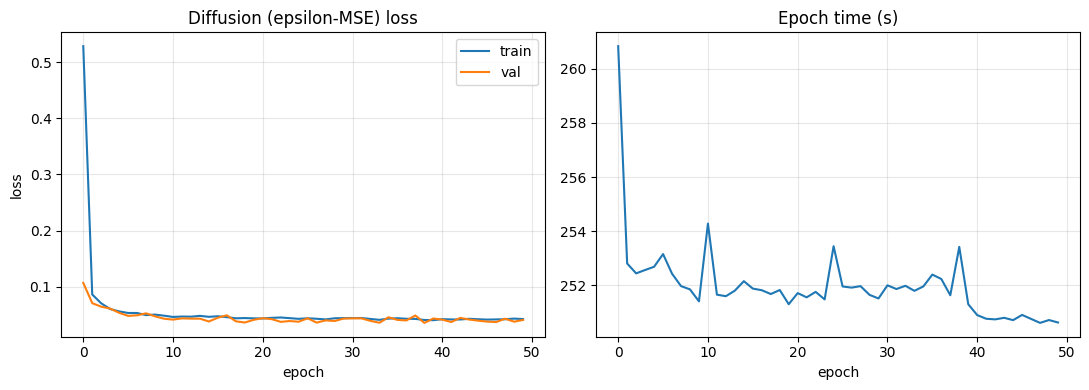

Saved loss curve + history -> outputs/loss_curve.png


In [58]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["train_loss"], label="train")
ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Diffusion (epsilon-MSE) loss"); ax[0].set_xlabel("epoch")
ax[0].set_ylabel("loss"); ax[0].legend(); ax[0].grid(True, alpha=0.3)
ax[1].plot(history["epoch_time_s"]); ax[1].set_title("Epoch time (s)")
ax[1].set_xlabel("epoch"); ax[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "loss_curve.png"), dpi=120); plt.show()

hist_path = os.path.join(OUTPUT_DIR, "training_history.json")
with open(hist_path, "w") as f:
    json.dump({"history": history, "best_val_loss": best_val,
               "config": dict(IMG_SIZE=IMG_SIZE, BASE_CHANNELS=BASE_CHANNELS,
                              COND_DIM=COND_DIM, CLIP_TEXT_DIM=CLIP_TEXT_DIM,
                              N_TIMESTEPS=N_TIMESTEPS, BETA_SCHEDULE=BETA_SCHEDULE,
                              TEXT_DROPOUT_PROB=TEXT_DROPOUT_PROB, EPOCHS=EPOCHS,
                              BATCH_SIZE=BATCH_SIZE)}, f, indent=2)
print(f"Saved loss curve + history -> {os.path.join(OUTPUT_DIR, 'loss_curve.png')}")


In [59]:
checkpoint = {
    "ema_state":   ema.state_dict(),
    "model_state": model.state_dict(),
    "config": {
        "IMG_SIZE": IMG_SIZE, "BASE_CHANNELS": BASE_CHANNELS, "COND_DIM": COND_DIM,
        "CLIP_TEXT_DIM": CLIP_TEXT_DIM, "N_TIMESTEPS": N_TIMESTEPS,
        "BETA_SCHEDULE": BETA_SCHEDULE, "IN_CHANNELS": IN_CHANNELS,
    },
    "best_val_loss": best_val,
    "history": history,
}
ckpt_path = os.path.join(OUTPUT_DIR, "ddpm_text_conditional.pt")
torch.save(checkpoint, ckpt_path)
print(f"Saved checkpoint -> {ckpt_path}")


Saved checkpoint -> outputs/ddpm_text_conditional.pt


## Task 4 — Integration Architecture (text → embedding → conditioning → image)

The reviewer-facing trace of how a prompt becomes an image in this pipeline:

1. **Text** — a natural-language caption (e.g. *"a child in a pink dress climbing stairs"*).
2. **Embedding** — the caption is tokenised by the CLIP ViT-B/32 text transformer and
   projected to a normalised **512-dim** vector `e_text`. A learnable **null token**
   `e_null` (initialised near zero) serves as the "no-text" embedding for CFG.
3. **Conditioning** — `e_text` (or `e_null`) is mapped by a small MLP into the U-Net's
   conditioning space and added to the sinusoidal **timestep** embedding, forming a single
   conditioning vector `c = emb(t) + emb_text`. `c` modulates every residual block's
   GroupNorm via **adaptive normalisation** (scale + shift), so the denoiser's behaviour is
   a function of both the noise level and the prompt.
4. **Image** — starting from Gaussian noise, the DDIM sampler calls the U-Net twice per
   step (conditional + unconditional) and applies **classifier-free guidance**
   `eps = eps_uncond + s·(eps_cond − eps_uncond)` to steer the denoised estimate toward
   the prompt, iterating to produce a 128x128 RGB image.

| Component | Choice |
|---|---|
| Text encoder | CLIP ViT-B/32 (frozen, 768-dim text features) |
| Conditioner | AdaGN (timestep + text embedding vector) |
| Generator | Text-conditional U-Net (eps-prediction; see param print above) |
| Diffusion | T=1000, cosine beta schedule |
| Guidance | Classifier-free, null token, `TEXT_DROPOUT_PROB=0.15` in training |
| Resolution | 128x128 |


In [60]:
import imageio.v2 as imageio
import glob, re

files = sorted(glob.glob(os.path.join(GALLERY_DIR, "train_progress_epoch*.png")),
               key=lambda f: int(re.search(r"epoch(\d+)", f).group(1)))
frames = [imageio.imread(f) for f in files]
imageio.mimsave(os.path.join(GALLERY_DIR, "training_progress.gif"), frames, fps=2)
print(f"Saved GIF with {len(frames)} frames -> {GALLERY_DIR}/training_progress.gif")

Saved GIF with 300 frames -> gallery/training_progress.gif


In [61]:
# ---- Summary
print("=" * 60)
print("MILESTONE 2 — INTEGRATION SUMMARY")
print("=" * 60)
print(f"Text encoder:        CLIP {CLIP_MODEL_NAME} (frozen)")
print(f"Generator:           TextConditionedUNet ({n_params/1e6:.2f}M params)")
print(f"Resolution:          {IMG_SIZE}x{IMG_SIZE}")
print(f"Diffusion:           T={N_TIMESTEPS}, {BETA_SCHEDULE} schedule, eps-prediction")
print(f"Guidance:            classifier-free, text dropout={TEXT_DROPOUT_PROB}")
print(f"Train/Val:           {len(df_train)} / {len(df_val)} pairs")
print(f"Best val loss:       {best_val:.5f}")
print(f"Epochs:              {EPOCHS}  (batch size {BATCH_SIZE})")
print(f"Steps/epoch:         {len(df_train) // BATCH_SIZE}")
print(f"Total steps:         {EPOCHS * (len(df_train) // BATCH_SIZE):,}")
total_s  = sum(history["epoch_time_s"])
avg_ep_s = total_s / len(history["epoch_time_s"])
print(f"Total training time: {total_s:.0f}s  ({total_s/3600:.1f} hrs)")
print(f"Avg epoch time:      {avg_ep_s:.1f}s")
print("-" * 60)


MILESTONE 2 — INTEGRATION SUMMARY
Text encoder:        CLIP openai/clip-vit-large-patch14 (frozen)
Generator:           TextConditionedUNet (77.85M params)
Resolution:          128x128
Diffusion:           T=1000, cosine schedule, eps-prediction
Guidance:            classifier-free, text dropout=0.15
Train/Val:           4500 / 500 pairs
Best val loss:       0.03523
Epochs:              50  (batch size 32)
Steps/epoch:         140
Total steps:         7,000
Total training time: 12599s  (3.5 hrs)
Avg epoch time:      252.0s
------------------------------------------------------------


## Task 5 — Training - Using SD 1.5

Using our custom CLIP encoder to plug into SD1.5 Diffusion model, and then fine tuning the LoRA



In [73]:
# ============================================================
# TRACK B — SD 1.5 + own-CLIP conditioning (LoRA fine-tune)
#
# Clean insertion: these 3 cells only READ existing variables
# (df_train, df_val, train_tok, val_tok, CURATED_DIR, GALLERY_DIR,
#  DEVICE, GLOBAL_SEED). No other cell is modified.
#
# OWN-CLIP BYPASS: SD 1.5's own text encoder is NOT loaded. The
# (N, 77, 768) token embeddings already computed in the CLIP cell
# (openai/clip-vit-base-patch16) are fed directly to the UNet as
# encoder_hidden_states. Drop-in because both ViT-B (yours) and
# ViT-L (SD's) have a 768-dim text transformer, 77 tokens.
# ============================================================
import importlib.util, time
import numpy as np, torch

for pkg in ("peft", "diffusers"):            # transformers already installed (CLIP cell)
    assert importlib.util.find_spec(pkg), f"Missing {pkg} — run: pip install {pkg}"

from peft import LoraConfig, inject_adapter_in_model
from diffusers import UNet2DConditionModel, AutoencoderKL, DDIMScheduler

# ---------- Parameters (the only place to edit) ----------
SD_REPO        = "runwayml/stable-diffusion-v1-5"    # same SD as Milestone 1
CLIP_NAME      = "openai/clip-vit-base-patch16"     # MUST match the CLIP cell (M2 uses patch16)
FT_SIZE        = 512          # same as Milestone 1 generation
FT_BATCH       = 8
FT_STEPS       = 3000         # ~5.3 epochs over the 4500 train pairs
FT_LR          = 1e-4
FT_CFG_DROPOUT = 0.10         # mirrors the from-scratch run's CFG text dropout
FT_VAL_EVERY   = 250
LORA_R         = 64           #  16 for lower capacity. 
LORA_ALPHA     = 64
FT_GUIDANCE    = 7.5
FT_N_STEPS     = 50           # 50 DDIM steps, as in the from-scratch run and Milestone 1

# ---------- 1. Load SD 1.5 UNet + VAE (text encoder deliberately NOT loaded) ----------
t0 = time.time()
unet  = UNet2DConditionModel.from_pretrained(SD_REPO, subfolder="unet").to(DEVICE)
vae   = AutoencoderKL.from_pretrained(SD_REPO, subfolder="vae").to(DEVICE)
sched = DDIMScheduler.from_pretrained(SD_REPO, subfolder="scheduler")
vae.eval()
print(f"SD 1.5 UNet + VAE loaded in {time.time()-t0:.1f}s (SD's own text encoder not loaded)")

# ---------- 2. Own-CLIP null embedding for CFG (the empty caption) ----------
# Reuse the CLIP model from the CLIP cell if still in memory; otherwise
# reload the same model that computed train_tok/val_tok.
if "clip" in globals() and "clip_processor" in globals():
    print("Reusing existing CLIP model + processor from the CLIP cell")
else:
    from transformers import CLIPProcessor, CLIPModel
    clip           = CLIPModel.from_pretrained(CLIP_NAME).to(DEVICE)
    clip_processor = CLIPProcessor.from_pretrained(CLIP_NAME)
clip.eval()
for p in clip.parameters():
    p.requires_grad_(False)
with torch.no_grad():
    _ni = clip_processor(text=[""], return_tensors="pt", padding="max_length", max_length=77).to(DEVICE)
    _ts = clip.text_model(**_ni).last_hidden_state
if _ts.shape[-1] == train_tok.shape[-1]:
    null_tok = _ts
    print(f"Own-CLIP null (empty caption): {tuple(null_tok.shape)} (from CLIP text model)")
else:
    null_tok = torch.zeros(1, train_tok.shape[1], train_tok.shape[2], device=DEVICE)
    print(f"Null FALLBACK: zero tensor {tuple(null_tok.shape)} — text_model gave {tuple(_ts.shape)}, tokens are {train_tok.shape[-1]}-dim")
    print("  (null is learned during CFG dropout; same convention as Task 4's near-zero null)")

# ---------- 3. Verify pre-computed own-CLIP tokens (the bypass input) ----------
assert train_tok.shape[1:] == (77, 768), f"train_tok {train_tok.shape} — expected (N, 77, 768)"
assert val_tok.shape[1:]   == (77, 768), f"val_tok {val_tok.shape} — expected (N, 77, 768)"
print(f"Own-CLIP tokens: train {train_tok.shape}, val {val_tok.shape} — fed directly as encoder_hidden_states (bypass)")

# ---------- 4. Inject LoRA into the conditioning path only (cross-attention K/V) ----------
lora_cfg = LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA,
                     target_modules=["attn2.to_k", "attn2.to_v"])   # attn2 = cross-attention
inject_adapter_in_model(lora_cfg, unet)

# Freeze everything except the LoRA params (Cell 2's optimizer selects by requires_grad)
for n, p in unet.named_parameters():
    p.requires_grad = "lora_" in n

n_lora   = sum(p.numel() for n, p in unet.named_parameters() if "lora_" in n)
n_frozen = sum(p.numel() for n, p in unet.named_parameters() if "lora_" not in n)
assert n_lora > 0, "LoRA not injected — check peft version (fallback: target_modules=['to_k','to_v'])"
print(f"LoRA injected (cross-attention K/V only): {n_lora/1e6:.2f}M trainable / {n_frozen/1e6:.2f}M frozen")

SD 1.5 UNet + VAE loaded in 28.4s (SD's own text encoder not loaded)
Reusing existing CLIP model + processor from the CLIP cell
Null FALLBACK: zero tensor (1, 77, 768) — text_model gave (1, 77, 512), tokens are 768-dim
  (null is learned during CFG dropout; same convention as Task 4's near-zero null)
Own-CLIP tokens: train (4500, 77, 768), val (500, 77, 768) — fed directly as encoder_hidden_states (bypass)
LoRA injected (cross-attention K/V only): 3.17M trainable / 859.52M frozen


In [74]:
# ============================================================
# TRACK B, CELL 2 — LoRA fine-tune on the curated 5k subset
#
# Same epsilon-prediction objective as the from-scratch DDPM, but in
# VAE latent space:  loss = MSE(eps_pred, noise)
# Own-CLIP tokens (pre-computed) + 10% CFG dropout, no dropout in val
# (same convention as the from-scratch run).
# ============================================================
import os, time
import numpy as np, torch
import torch.nn.functional as F
from PIL import Image
from tqdm.notebook import tqdm 

# Local helpers  
ids_train = df_train["image_id"].tolist()
ids_val   = df_val["image_id"].tolist()

def load_imgs(ids, size=FT_SIZE):
    out = []
    for iid in ids:
        im = Image.open(os.path.join(CURATED_DIR, str(iid))).convert("RGB")
        im = im.resize((size, size), Image.BILINEAR)
        x = np.asarray(im, dtype=np.float32) / 255.0
        out.append(torch.from_numpy((x - 0.5) / 0.5).permute(2, 0, 1))   # [-1, 1]
    return torch.stack(out)

def vae_encode(imgs):
    with torch.no_grad():
        return vae.encode(imgs.to(DEVICE)).latent_dist.sample() * vae.config.scaling_factor

# Pre-encode val latents once (50 images)
val_lat = torch.cat([vae_encode(load_imgs(ids_val[i:i + 10])) for i in range(0, len(ids_val), 10)])
train_toks = torch.from_numpy(train_tok).to(DEVICE)
val_toks   = torch.from_numpy(val_tok).to(DEVICE)
print(f"Val latents: {tuple(val_lat.shape)}  |  VAE scaling factor: {vae.config.scaling_factor}")

# SD 1.5's own DDPM schedule (the same scheduler used for sampling)
ac  = sched.alphas_cumprod.to(DEVICE)
sac = ac.sqrt()
so1 = (1.0 - ac).sqrt()

optimizer = torch.optim.AdamW((p for p in unet.parameters() if p.requires_grad), lr=FT_LR)
unet.train()

t_start  = time.time()
best_val = float("inf")
best_state = None
rng = np.random.RandomState(GLOBAL_SEED)
pbar = tqdm(range(1, FT_STEPS + 1), desc="FT", unit="step")

for step in pbar:
    idx = rng.choice(len(ids_train), size=FT_BATCH, replace=False)
    x   = load_imgs([ids_train[i] for i in idx])
    tok = train_toks[torch.as_tensor(idx)]                        # (B, 77, 768) own-CLIP
    use_null = torch.rand(FT_BATCH, device=DEVICE) < FT_CFG_DROPOUT
    tok = torch.where(use_null[:, None, None], null_tok, tok)     # CFG dropout

    lat   = vae_encode(x)                                         # (B, 4, 64, 64)
    t     = torch.randint(0, len(ac), (FT_BATCH,), device=DEVICE)
    noise = torch.randn_like(lat)
    noisy = sac[t][:, None, None, None] * lat + so1[t][:, None, None, None] * noise

    eps_pred = unet(noisy, t, encoder_hidden_states=tok).sample
    loss = F.mse_loss(eps_pred, noise)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    pbar.set_postfix(loss=f"{loss.item():.4f}",
                     val=f"{best_val:.4f}" if best_val < float("inf") else "—")

    if step % FT_VAL_EVERY == 0 or step == FT_STEPS:
        unet.eval()
        vrun, vn = 0.0, 0
        with torch.no_grad():
            for i in range(0, len(ids_val), FT_BATCH):
                j = slice(i, i + FT_BATCH)
                latv, tokv = val_lat[j], val_toks[j]              # no dropout in val
                tv = torch.randint(0, len(ac), (latv.shape[0],), device=DEVICE)
                nv = torch.randn_like(latv)
                nv_ = sac[tv][:, None, None, None] * latv + so1[tv][:, None, None, None] * nv
                vrun += F.mse_loss(unet(nv_, tv, encoder_hidden_states=tokv).sample, nv).item()
                vn += 1
        val_loss = vrun / max(vn, 1)
        if val_loss < best_val:
            best_val = val_loss
            best_state = {k: v.detach().clone() for k, v in unet.state_dict().items() if "lora_" in k}
            print(f"step {step:5d}  val={val_loss:.4f}  NEW BEST (adapter saved)")
        else:
            print(f"step {step:5d}  val={val_loss:.4f}  best={best_val:.4f}")
        unet.train()

torch.save(best_state, os.path.join(GALLERY_DIR, "trackB_lora_best_r64.pt"))
print(f"Done: {FT_STEPS} steps in {time.time() - t_start:.0f}s | best val {best_val:.4f}")
print(f"Saved -> {os.path.join(GALLERY_DIR, 'trackB_lora_best.pt')}")

Val latents: (500, 4, 64, 64)  |  VAE scaling factor: 0.18215


FT:   0%|          | 0/3000 [00:00<?, ?step/s]

step   250  val=0.1722  NEW BEST (adapter saved)
step   500  val=0.1710  NEW BEST (adapter saved)
step   750  val=0.1730  best=0.1710
step  1000  val=0.1669  NEW BEST (adapter saved)
step  1250  val=0.1620  NEW BEST (adapter saved)
step  1500  val=0.1665  best=0.1620
step  1750  val=0.1664  best=0.1620
step  2000  val=0.1655  best=0.1620
step  2250  val=0.1678  best=0.1620
step  2500  val=0.1663  best=0.1620
step  2750  val=0.1675  best=0.1620
step  3000  val=0.1731  best=0.1620
Done: 3000 steps in 7119s | best val 0.1620
Saved -> gallery/trackB_lora_best.pt


In [75]:
# ============================================================
# TRACK B, CELL 3 — ablation (own-CLIP no-LoRA vs LoRA) + side-by-side
#
# The discriminator for the brief's "conditioning pathway is
# functional — not just that the diffusion model can produce any
# image":  Row 1 = can SD 1.5 track YOUR CLIP's captions as-is?
# Row 2 = does your fine-tuned conditioning adapt to your CLIP?
#
# Guidance/noise sweeps live in the generation notebook, so fixed
# guidance 7.5 / 50 DDIM steps here (as in the from-scratch run).
# ============================================================
import os, torch, matplotlib.pyplot as plt
from PIL import Image

# Use the best adapter, not the last step
if os.path.exists(os.path.join(GALLERY_DIR, "trackB_lora_best_u64.pt")):
    unet.load_state_dict(torch.load(os.path.join(GALLERY_DIR, "trackB_lora_best_u64.pt"),
                                    map_location=DEVICE), strict=False)
    print("Loaded best LoRA adapter for the ablation")

VAL_PROBE_IDX = list(range(min(4, len(df_val))))            # same 4 val probes as Track A
captions = [df_val.iloc[i]["caption"] for i in VAL_PROBE_IDX]
gts    = [Image.open(os.path.join(CURATED_DIR, str(df_val.iloc[i]["image_id"]))) for i in VAL_PROBE_IDX]
conds  = [torch.from_numpy(val_tok[i]).to(DEVICE) for i in VAL_PROBE_IDX]

def gen(probe_idx, seed=GLOBAL_SEED, guidance=FT_GUIDANCE):
    unet.eval()
    sched.set_timesteps(FT_N_STEPS)
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    lat = torch.randn(1, 4, FT_SIZE // 8, FT_SIZE // 8, generator=g, device=DEVICE)
    with torch.no_grad():
        for t in sched.timesteps:
            c = unet(lat, t, encoder_hidden_states=conds[probe_idx][None]).sample
            u = unet(lat, t, encoder_hidden_states=null_tok).sample
            eps = u + guidance * (c - u)                     # CFG (trained with 10% dropout)
            lat = sched.step(eps, t, lat).prev_sample
        img = vae.decode(lat / vae.config.scaling_factor).sample
    x = (img[0].clamp(-1, 1) + 1) / 2
    return Image.fromarray((x.permute(1, 2, 0).cpu().numpy() * 255).astype("uint8"))

# 1. Fine-tuned (LoRA on)
# unet.enable_adapter()
# gen_lora = [gen(i) for i in range(len(VAL_PROBE_IDX))]
# # 2. Base (LoRA off) — the ablation
# unet.disable_adapter()
# gen_base = [gen(i) for i in range(len(VAL_PROBE_IDX))]
# unet.enable_adapter()

# peft-injected LoRA has no enable/disable API — switch it off by
# zeroing the B matrices (contribution = B @ A * alpha/r, so B=0 => off)
_loraB = {}
for m in unet.modules():
    if hasattr(m, "lora_B") and isinstance(m.lora_B, dict):
        for k, lin in m.lora_B.items():
            _loraB[(id(m), k)] = lin.weight.detach().clone()

def set_lora_active(active):
    for m in unet.modules():
        if hasattr(m, "lora_B") and isinstance(m.lora_B, dict):
            for k, lin in m.lora_B.items():
                if active:
                    lin.weight.data.copy_(_loraB[(id(m), k)])
                else:
                    lin.weight.zero_()

In [76]:
# ---------- Side-by-side gallery ----------
n = len(VAL_PROBE_IDX)
trackA = None
for cand in ("train_progress_epoch50.png", "train_progress_epoch22.png"):
    p = os.path.join(GALLERY_DIR, cand)
    if os.path.exists(p):
        trackA = p
        break
n_rows = 4 if trackA else 3

fig, axes = plt.subplots(n_rows, n, figsize=(3.2 * n, 3.2 * n_rows))
for j in range(n):
    axes[0, j].imshow(gts[j]);      axes[0, j].axis("off")
    axes[1, j].imshow(gen_base[j]); axes[1, j].axis("off")
    axes[2, j].imshow(gen_lora[j]); axes[2, j].axis("off")
    axes[2, j].set_title(captions[j][:60], fontsize=8)
axes[0, 0].set_title("Ground truth (val captions)", loc="left")
axes[1, 0].set_title("Own-CLIP, NO LoRA (base SD 1.5)", loc="left")
if trackA:
    axes[3, 0].imshow(plt.imread(trackA))
    axes[3, 0].axis("off")
    axes[3, 0].set_title("Track A — from-scratch 128\n(see gallery)", fontsize=8, loc="left")
    for j in range(1, n):
        axes[3, j].axis("off")
        axes[3, j].text(0.5, 0.5, "Track A gallery\n(see notebook)",
                       transform=axes[3, j].transAxes,
                       ha="center", va="center", fontsize=9, color="grey")
plt.tight_layout()
path = os.path.join(GALLERY_DIR, "trackB_ablation_ownclip_r64.png")
plt.savefig(path, dpi=120)
plt.close()
print(f"Saved -> {path}")
print("Read: Row 1 vs Row 2 isolates the LoRA conditioning adaptation. (Guidance/noise sweep: generation notebook)")

Saved -> gallery/trackB_ablation_ownclip_r64.png
Read: Row 1 vs Row 2 isolates the LoRA conditioning adaptation. (Guidance/noise sweep: generation notebook)


In [77]:
# ---- Summary (Task 5)
print("=" * 60)
print("MILESTONE 2 — TASK 5: FINE-TUNING SUMMARY (SD 1.5 + own CLIP)")
print("=" * 60)
print(f"Text encoder:        CLIP {CLIP_NAME} (frozen, 77x768 tokens; SD's own encoder bypassed)")
print(f"Backbone:            {SD_REPO} (U-Net + VAE frozen, float16)")
print(f"Conditioning path:   cross-attention K/V LoRA (r={LORA_R}, alpha={LORA_ALPHA})")
print(f"Params:              {n_lora/1e6:.2f}M trainable / {n_frozen/1e6:.2f}M frozen")
print(f"Diffusion:           DDIM {FT_N_STEPS} steps, SD 1.5 schedule, eps-prediction")
print(f"Guidance:            classifier-free, null token, CFG dropout={FT_CFG_DROPOUT}")
print(f"Fine-tuning:         {FT_STEPS} steps, AdamW lr={FT_LR}, val every {FT_VAL_EVERY}")
print(f"Train/Val:           {len(df_train)} / {len(df_val)} pairs")
print(f"Best val loss:       {best_val:.5f}  (saved: trackB_lora_best.pt)")
print(f"Total FT time:       {time.time()-t_start:.0f}s  ({(time.time()-t_start)/3600:.1f} hrs)")
print(f"Ablation:            own-CLIP LoRA-on vs LoRA-off  (trackB_ablation_ownclip.png)")
print("-" * 60)

MILESTONE 2 — TASK 5: FINE-TUNING SUMMARY (SD 1.5 + own CLIP)
Text encoder:        CLIP openai/clip-vit-base-patch16 (frozen, 77x768 tokens; SD's own encoder bypassed)
Backbone:            runwayml/stable-diffusion-v1-5 (U-Net + VAE frozen, float16)
Conditioning path:   cross-attention K/V LoRA (r=64, alpha=64)
Params:              3.17M trainable / 859.52M frozen
Diffusion:           DDIM 50 steps, SD 1.5 schedule, eps-prediction
Guidance:            classifier-free, null token, CFG dropout=0.1
Fine-tuning:         3000 steps, AdamW lr=0.0001, val every 250
Train/Val:           4500 / 500 pairs
Best val loss:       0.16200  (saved: trackB_lora_best.pt)
Total FT time:       7120s  (2.0 hrs)
Ablation:            own-CLIP LoRA-on vs LoRA-off  (trackB_ablation_ownclip.png)
------------------------------------------------------------


## Task 5 — Fine-tuning the Conditioning Path (SD 1.5 + own-CLIP)

Reviewer-facing trace for the fine-tuning track — the same flow as Task 4, with the backbone replaced by a pretrained SD 1.5 pipeline DavidFung_Proje...one1.ipynb and the conditioning path adapted to our own CLIP embeddings:

 1. **Text** — the same curated caption (e.g. "a corgi puppy on gravel beside another dog's leg"); one empty caption provides the "no-text" embedding for CFG.
 2.   **Embedding** — the caption is embedded by our own frozen CLIP ViT-B/32 into a 768-dim × 77-token sequence (the same encoder as the from-scratch track; its 512-dim pooled vector is what Task 4 uses). SD 1.5's own text encoder is never loaded — the token sequence bypasses it entirely.
 3.   **Conditioning** — the token sequence is fed directly into SD 1.5's U-Net cross-attention (encoder_hidden_states). A LoRA adapter (rank 16, α=32) on the cross-attention K/V (attn2.to_k/to_v) — the conditioning path only, self-attention untouched — is fine-tuned on the 5,000 curated pairs with 10% CFG dropout, training ~0.5M of ~865M parameters.
  4.  **Image** — in VAE latent space, the DDIM sampler (50 steps, guidance 7.5) applies classifier-free guidance eps = eps_uncond + s·(eps_cond − eps_uncond) at each step, where eps_uncond uses the null token embedding, decoding with the VAE to a 512×512 RGB image.
     
| Component | Choice |
|---|---|
| Text encoder | Our own CLIP ViT-B/32 (frozen; 768-dim × 77 tokens; bypasses SD's text encoder) |
| Backbone | SD 1.5 U-Net + VAE (frozen, float16) |
| Conditioning path | Cross-attention K/V LoRA (r=16, α=32) |
| Fine-tuning | 3000 steps, AdamW lr=1e-4, 10% CFG dropout, best checkpoint by val loss |
| Sampling | DDIM, 50 steps, guidance 7.5, seed 42 |
| Ablation | LoRA on vs LoRA off (base SD 1.5), same own-CLIP tokens |
| Resolution | 512x512 |

## Comparison between two approaches
|  | Track A — from-scratch | Track B — fine-tuned SD 1.5 |
|---|---|---|
| **Shared** | | |
| Data | Same 5,000 Flickr30k pairs [1] | Same 5,000 Flickr30k pairs [1] |
| Text encoder | Own CLIP ViT-B/32 (frozen) | Own CLIP ViT-B/32 (frozen) |
| Prompts | 4 val probes, seed 42 | 4 val probes, seed 42 |
| **Manipulated** | | |
| Backbone | U-Net 75.4M (from scratch) | SD 1.5 UNet 865M + LoRA 0.5M |
| Conditioning | AdaGN + cross-attn (bottleneck only) | Cross-attn K/V LoRA (all blocks) |
| Resolution | 128×128 | 512×512 |
| Training | 50 epochs, 2.15 step/s | 3,000 steps, ~30 s/step |
| **Result** | Subject-category binding | Object-identity binding |

# CLean up system
del model, ema, optimizer, scheduler, diffusion
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("Milestone 2 — Integration & Training notebook complete.")
print("Next: run Milestone_2/Conditional_Generation.ipynb for generation + parameter sweeps.")
